# Plant Disease Recognition Using EfficientNetB4

This is the final improved version of the uploaded training notebook. It keeps the original Mendeley dataset, `splitfolders` 80/10/10 split, 160×160 images, batch size 32, EfficientNetB4 ImageNet backbone, feature extraction, and fine-tuning workflow.

Improvements included:
- Softmax output for single-label multi-class classification.
- Training-only data augmentation.
- Early stopping, best-model checkpointing, and learning-rate reduction.
- Lower learning rate during fine-tuning.
- Frozen BatchNormalization layers during fine-tuning.
- Test-set evaluation with precision, recall, F1-score, classification report, and confusion matrix.
- Consistent class-index ordering and model/label saving.

Run the cells from top to bottom in Google Colab.

## 1. Download and extract the dataset

In [25]:
!wget -O "dataset.zip" "https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/b4e3a32f-c0bd-4060-81e9-6144231f2520/file_downloaded"
!unzip -q -o /content/dataset.zip -d /content/

--2026-11-12 07:59:49--  https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/b4e3a32f-c0bd-4060-81e9-6144231f2520/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/349ac012-2948-4172-bbba-3bf8f76596fd [following]
--2026-11-12 07:59:49--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/349ac012-2948-4172-bbba-3bf8f76596fd
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 3.5.99.122, 3.5.75.32, 3.5.69.48, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|3.5.99.122|:443... connec

## 2. Install and import libraries

In [26]:
!pip -q install split-folders scikit-learn seaborn

import os
import json
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import splitfolders

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Set configuration and reproducibility

In [27]:
SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

BATCH_SIZE = 32
IMG_SIZE = (160, 160)

INITIAL_EPOCHS = 6
FINE_TUNE_EPOCHS = 3

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

AUTOTUNE = tf.data.AUTOTUNE

DATASET_SOURCE = "/content/Plant_leave_diseases_dataset_with_augmentation"
SPLIT_OUTPUT = "/content/dataset"

MODEL_DIR = "/content/models"
OUTPUT_DIR = "/content/outputs"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.isdir(DATASET_SOURCE):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_SOURCE}. "
        "Check the extracted ZIP contents and update DATASET_SOURCE if needed."
    )

## 4. Split dataset into training, validation, and test sets

In [28]:
# Remove old split folders so the split is recreated consistently.
if os.path.exists(SPLIT_OUTPUT):
    shutil.rmtree(SPLIT_OUTPUT)

splitfolders.ratio(
    DATASET_SOURCE,
    output=SPLIT_OUTPUT,
    seed=SEED,
    ratio=(0.8, 0.1, 0.1)
)

train_dir = os.path.join(SPLIT_OUTPUT, "train")
validation_dir = os.path.join(SPLIT_OUTPUT, "val")
test_dir = os.path.join(SPLIT_OUTPUT, "test")

Copying files: 61486 files [00:15, 4015.94 files/s]


## 5. Load image datasets

Validation and test datasets use `shuffle=False` so predictions remain aligned with their true labels during evaluation.

In [29]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    shuffle=True,
    seed=SEED,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    label_mode="int"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    label_mode="int"
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    label_mode="int"
)

class_names = train_dataset.class_names
num_classes = len(class_names)

# Ensure all splits use exactly the same class-to-index mapping.
assert validation_dataset.class_names == class_names
assert test_dataset.class_names == class_names

print("Number of classes:", num_classes)
print("Class names:", class_names)

with open(os.path.join(OUTPUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=2)

Found 49179 files belonging to 39 classes.
Found 6139 files belonging to 39 classes.
Found 6168 files belonging to 39 classes.
Number of classes: 39
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight

## 6. Visualize training images

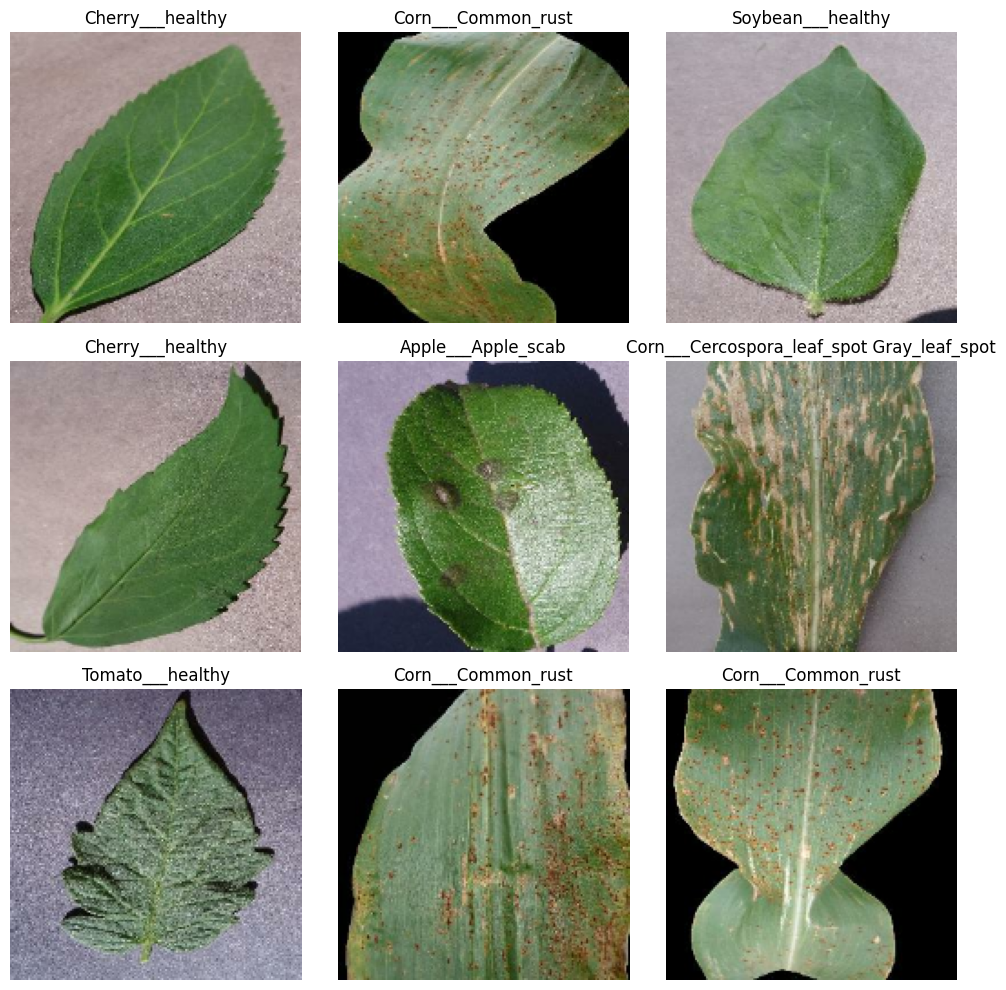

In [30]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Optimize dataset loading

In [31]:
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

## 8. Build EfficientNetB4

The original EfficientNetB4 backbone is retained. Keras EfficientNet includes its input rescaling internally, so image batches should remain in the 0–255 range. Do not divide inputs by 255 before passing them to this model.

The augmentation layers execute during training and are inactive during evaluation/inference.

In [32]:
IMG_SHAPE = IMG_SIZE + (3,)

base_model = tf.keras.applications.EfficientNetB4(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained convolutional base for initial feature extraction.
base_model.trainable = False

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.08),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomContrast(0.10)
    ],
    name="data_augmentation"
)

inputs = tf.keras.Input(shape=IMG_SHAPE)

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)

# Softmax is appropriate because each image belongs to one disease class.
outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax",
    name="predictions"
)(x)

model = tf.keras.Model(inputs, outputs, name="plant_disease_efficientnetb4")

model.summary()

Model: "plant_disease_efficientnetb4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb4 (Functional)     │ (None, 5, 5, 1792)     │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1792)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 39)             │        69,927 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,743,750 (67.69 MB)

 Trainable params: 69,927 (273.15 KB)

 Non-trainable params: 17,673,823 (67.42 MB)

## 9. Compile model and define callbacks

In [33]:
def create_callbacks(checkpoint_path):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

feature_checkpoint = os.path.join(
    MODEL_DIR, "efficientnetb4_feature_extraction.keras"
)

## 10. Feature extraction training

In [34]:
history = model.fit(
    train_dataset,
    epochs=INITIAL_EPOCHS,
    validation_data=validation_dataset,
    callbacks=create_callbacks(feature_checkpoint)
)

Epoch 1/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.6579 - loss: 1.3355
Epoch 1: val_loss improved from None to 0.39003, saving model to /content/models/efficientnetb4_feature_extraction.keras

Epoch 1: finished saving model to /content/models/efficientnetb4_feature_extraction.keras
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 222s 130ms/step - accuracy: 0.7798 - loss: 0.8369 - val_accuracy: 0.8920 - val_loss: 0.3900 - learning_rate: 0.0010
Epoch 2/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8671 - loss: 0.4560
Epoch 2: val_loss improved from 0.39003 to 0.29851, saving model to /content/models/efficientnetb4_feature_extraction.keras

Epoch 2: finished saving model to /content/models/efficientnetb4_feature_extraction.keras
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 193s 125ms/step - accuracy: 0.8751 - loss: 0.4236 - val_accuracy: 0.9104 - val_loss: 0.2985 - learning_rate: 0.0010
Epoch 3/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8870 - loss: 0.3702
Epoch 3: val

## 11. Fine-tune EfficientNetB4

In [35]:
# Unfreeze the backbone, then freeze its earlier layers.
base_model.trainable = True

fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total backbone layers:", len(base_model.layers))
print("Fine-tuning begins at layer:", fine_tune_at)
print("Trainable variables:", len(model.trainable_variables))

# Recompile after changing trainable flags and use a much smaller learning rate.
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

fine_tune_checkpoint = os.path.join(
    MODEL_DIR, "efficientnetb4_finetuned.keras"
)

history_fine = model.fit(
    train_dataset,
    epochs=FINE_TUNE_EPOCHS,
    validation_data=validation_dataset,
    callbacks=create_callbacks(fine_tune_checkpoint)
)

Total backbone layers: 475
Fine-tuning begins at layer: 100
Trainable variables: 179
Epoch 1/3
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.9369 - loss: 0.1907
Epoch 1: val_loss improved from None to 0.08571, saving model to /content/models/efficientnetb4_finetuned.keras

Epoch 1: finished saving model to /content/models/efficientnetb4_finetuned.keras
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 441s 263ms/step - accuracy: 0.9509 - loss: 0.1482 - val_accuracy: 0.9707 - val_loss: 0.0857 - learning_rate: 1.0000e-05
Epoch 2/3
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.9709 - loss: 0.0885
Epoch 2: val_loss improved from 0.08571 to 0.06973, saving model to /content/models/efficientnetb4_finetuned.keras

Epoch 2: finished saving model to /content/models/efficientnetb4_finetuned.keras
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 399s 260ms/step - accuracy: 0.9752 - loss: 0.0760 - val_accuracy: 0.9754 - val_loss: 0.0697 - learning_rate: 1.0000e-05
Epoch 3/3
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 0s 

## 12. Plot training and validation curves

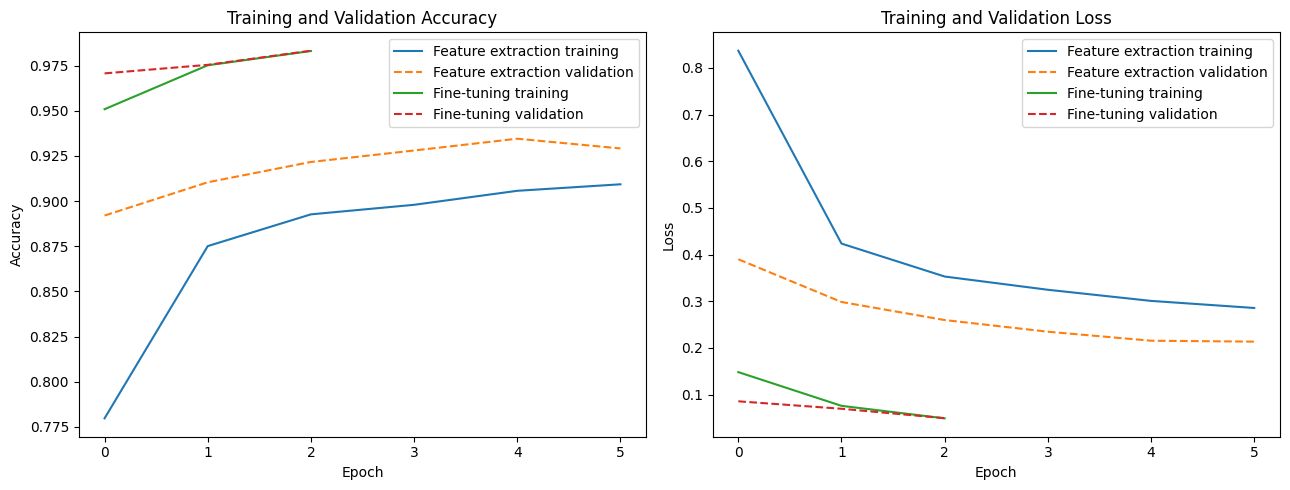

In [36]:
def plot_history(histories, labels):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for hist, label in zip(histories, labels):
        axes[0].plot(hist.history["accuracy"], label=f"{label} training")
        axes[0].plot(hist.history["val_accuracy"], linestyle="--",
                     label=f"{label} validation")

        axes[1].plot(hist.history["loss"], label=f"{label} training")
        axes[1].plot(hist.history["val_loss"], linestyle="--",
                     label=f"{label} validation")

    axes[0].set_title("Training and Validation Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].set_title("Training and Validation Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "training_history.png"),
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

plot_history(
    [history, history_fine],
    ["Feature extraction", "Fine-tuning"]
)

## 13. Load the best fine-tuned model and evaluate on the test set

The checkpoint is selected using validation loss. The test set is used only for final evaluation, not for model selection.

In [37]:
best_model = tf.keras.models.load_model(fine_tune_checkpoint)

test_loss, test_accuracy = best_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

193/193 ━━━━━━━━━━━━━━━━━━━━ 26s 106ms/step - accuracy: 0.9828 - loss: 0.0492
Test loss: 0.0492
Test accuracy: 0.9828


## 14. Classification report and evaluation metrics

In [38]:
y_true = []
y_probabilities = []

for image_batch, label_batch in test_dataset:
    batch_probabilities = best_model.predict(
        image_batch,
        verbose=0
    )

    y_true.extend(label_batch.numpy().astype(int))
    y_probabilities.extend(batch_probabilities)

y_true = np.asarray(y_true)
y_probabilities = np.asarray(y_probabilities)
y_pred = np.argmax(y_probabilities, axis=1)

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1_score, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1_score:.4f}")

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
)

print("\\nClassification Report:\\n")
print(report)

with open(
    os.path.join(OUTPUT_DIR, "classification_report.txt"),
    "w"
) as f:
    f.write(report)

metrics = {
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "weighted_precision": float(precision),
    "weighted_recall": float(recall),
    "weighted_f1_score": float(f1_score),
    "number_of_test_images": int(len(y_true)),
    "number_of_classes": int(num_classes)
}

with open(
    os.path.join(OUTPUT_DIR, "test_metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=2)

display(pd.DataFrame([metrics]))

Accuracy:  0.9828
Precision: 0.9833
Recall:    0.9828
F1-score:  0.9828
\nClassification Report:\n
                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.97      0.99      0.98       100
                            Apple___Black_rot       1.00      0.99      0.99       100
                     Apple___Cedar_apple_rust       1.00      1.00      1.00       100
                              Apple___healthy       0.99      0.98      0.99       165
                    Background_without_leaves       1.00      1.00      1.00       115
                          Blueberry___healthy       1.00      1.00      1.00       151
                      Cherry___Powdery_mildew       1.00      1.00      1.00       106
                             Cherry___healthy       1.00      0.99      0.99       100
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.94      0.94       100
                           Cor

,test_loss,accuracy,weighted_precision,weighted_recall,weighted_f1_score,number_of_test_images,number_of_classes
0,0.049228,0.982815,0.983308,0.982815,0.982831,6168,39


## 15. Confusion matrix

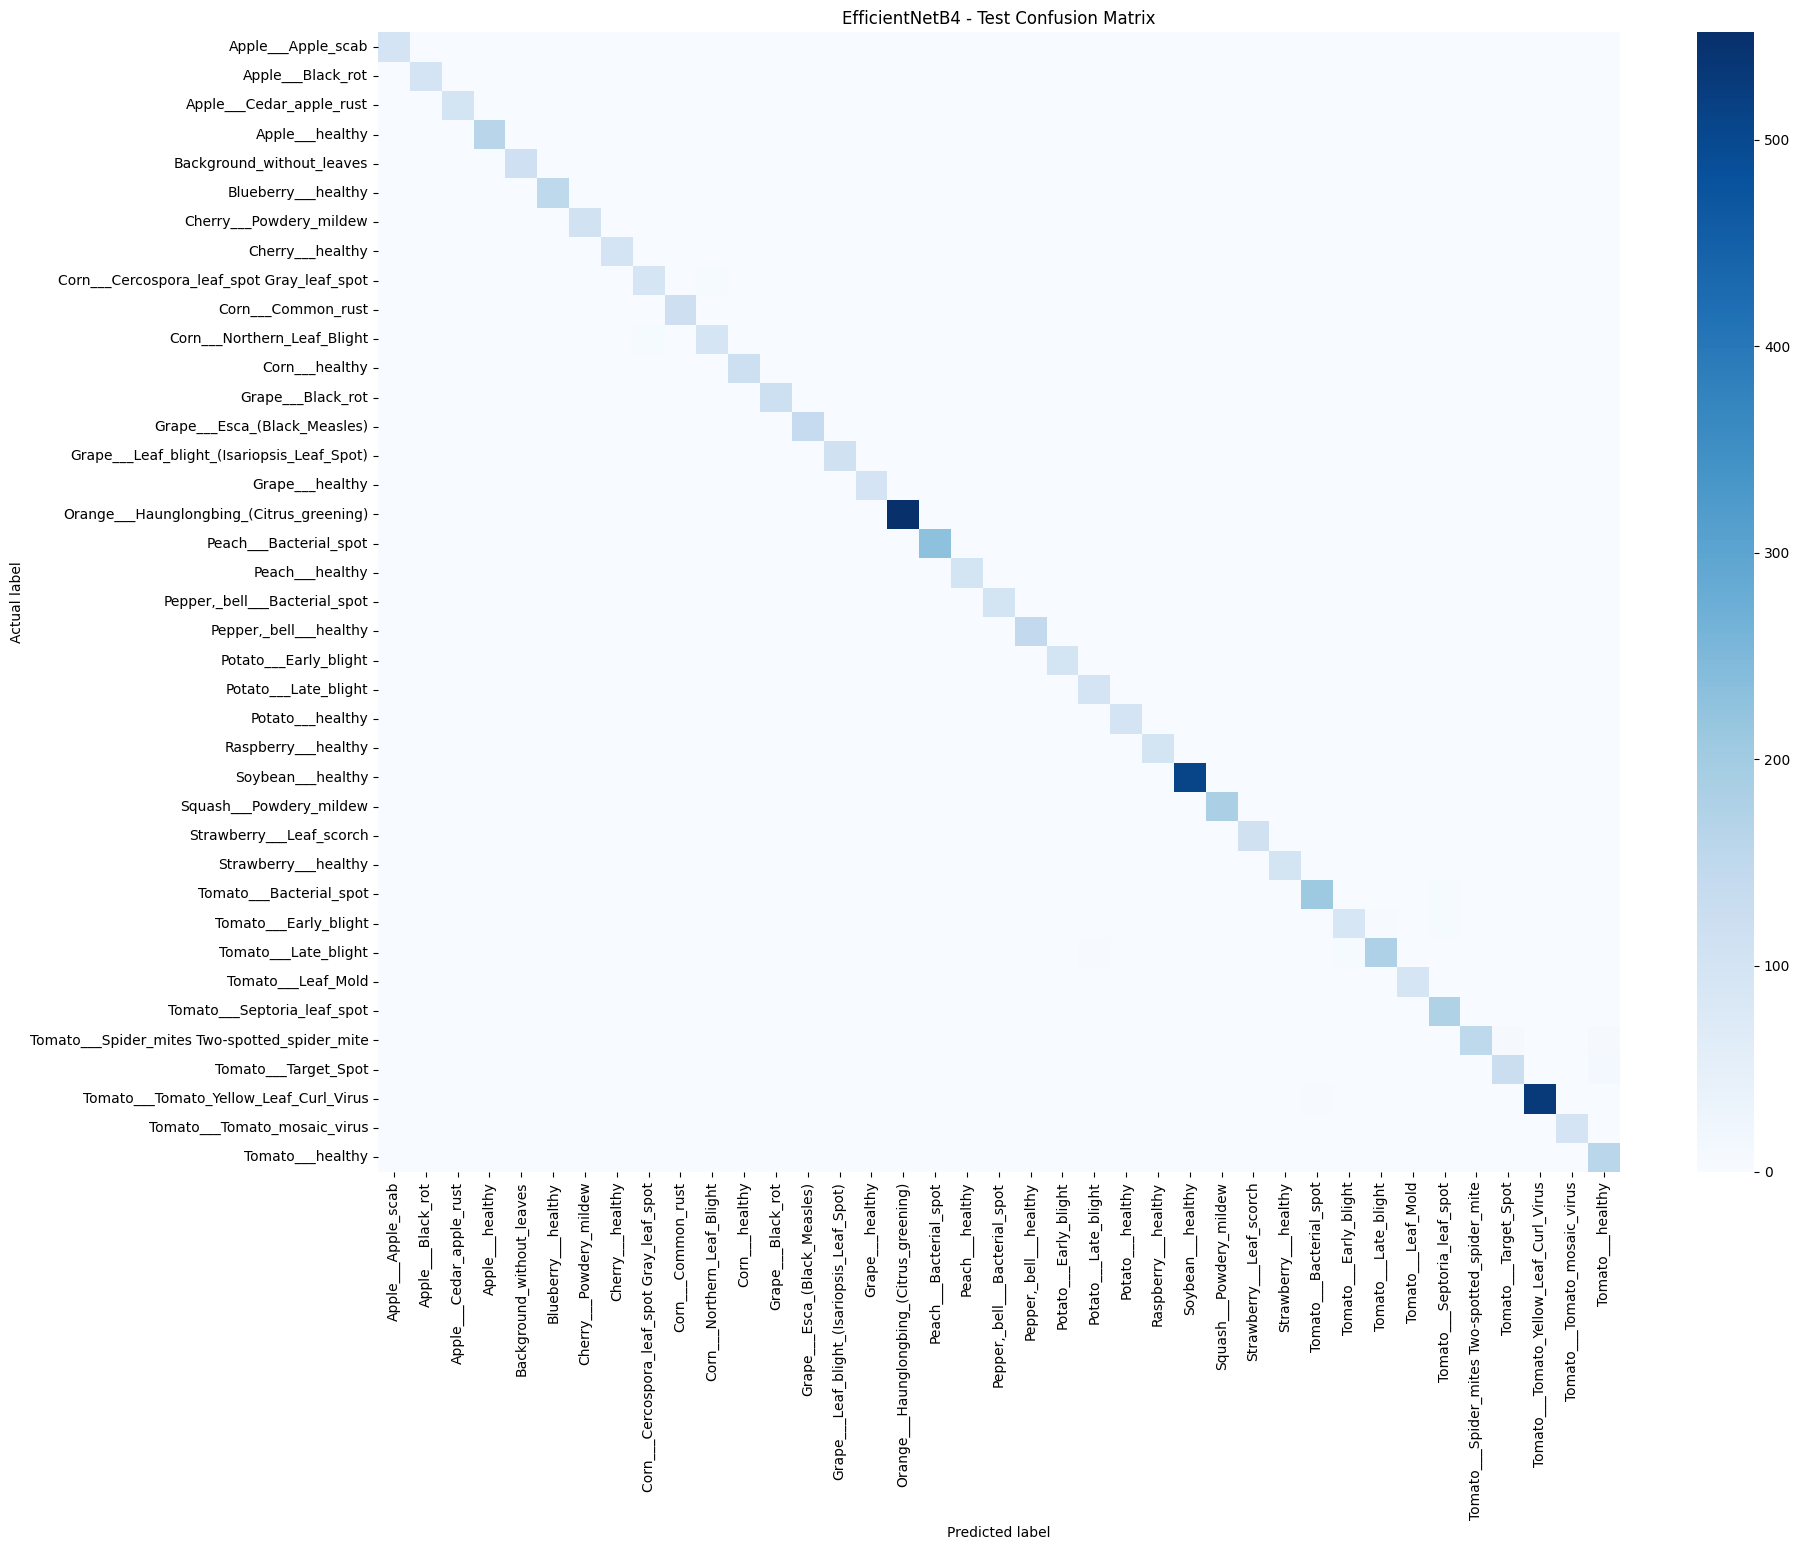

In [39]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(max(12, num_classes * 0.5),
                    max(10, num_classes * 0.4)))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("EfficientNetB4 - Test Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=180,
    bbox_inches="tight"
)
plt.show()

## 16. Display sample predictions

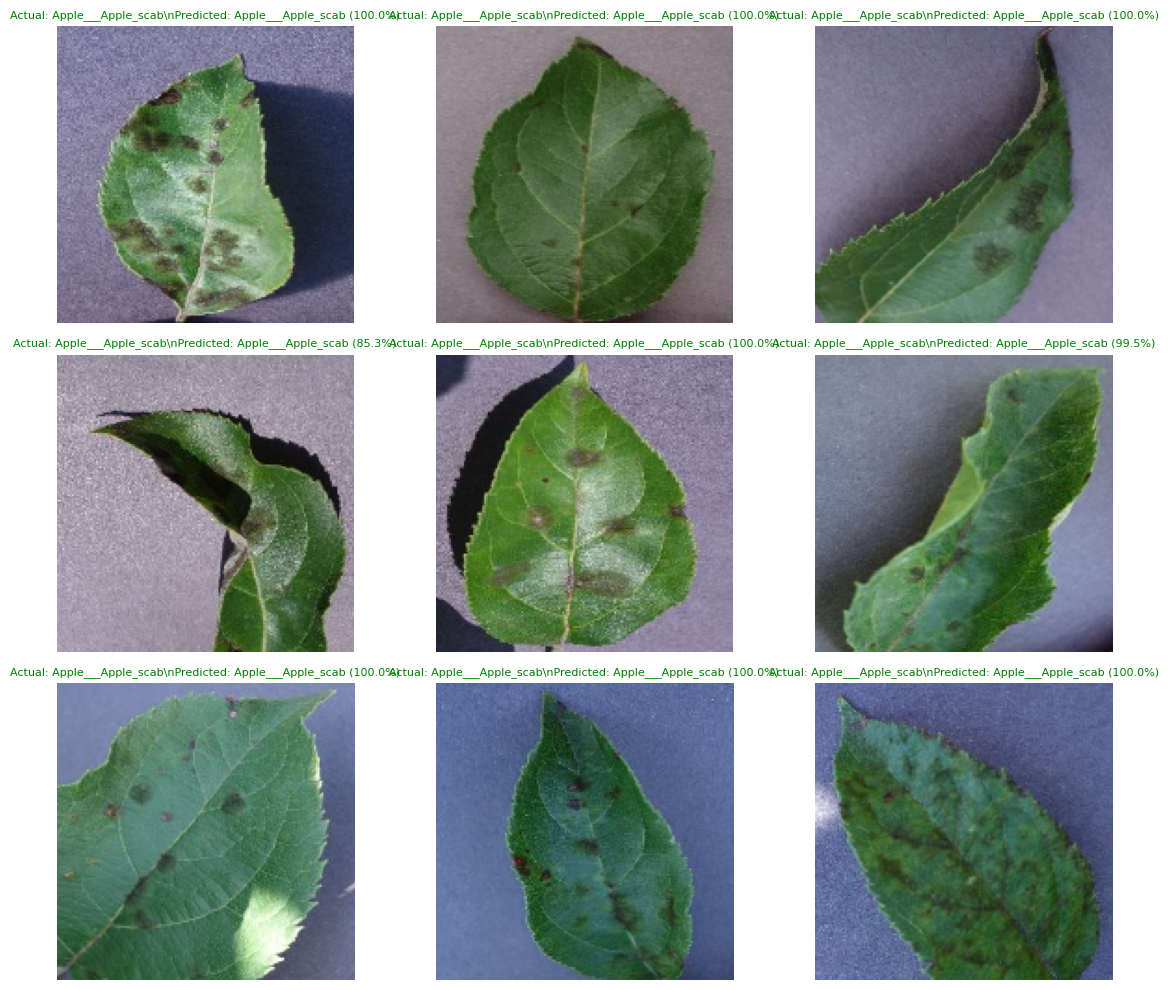

In [40]:
# Test dataset is not shuffled, and predictions correspond to these labels.
for image_batch, label_batch in test_dataset.take(1):
    probabilities = best_model.predict(image_batch, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    plt.figure(figsize=(12, 10))

    for i in range(min(9, len(image_batch))):
        ax = plt.subplot(3, 3, i + 1)

        true_label = class_names[int(label_batch[i])]
        predicted_label = class_names[int(predictions[i])]
        confidence = float(np.max(probabilities[i])) * 100

        plt.imshow(image_batch[i].numpy().astype("uint8"))
        ax.set_title(
            f"Actual: {true_label}\\n"
            f"Predicted: {predicted_label} ({confidence:.1f}%)",
            color="green" if true_label == predicted_label else "red",
            fontsize=8
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## 17. Save the final model and class names

In [41]:
final_model_path = os.path.join(
    MODEL_DIR, "plant_disease_efficientnetb4.keras"
)

best_model.save(final_model_path)

with open(
    os.path.join(MODEL_DIR, "class_names.json"),
    "w"
) as f:
    json.dump(class_names, f, indent=2)

print("Model saved to:", final_model_path)
print("Class names saved.")

Model saved to: /content/models/plant_disease_efficientnetb4.keras
Class names saved.


## 18. Prediction function for a new leaf image

In [43]:
def predict_disease(image_path, top_k=5):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE,
        color_mode="rgb"
    )

    image_array = tf.keras.utils.img_to_array(image).astype(np.float32)

    # Do not divide by 255: EfficientNet's preprocessing is built into the model.
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = best_model.predict(image_array, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:top_k]

    results = []
    for index in top_indices:
        results.append({
            "disease": class_names[int(index)],
            "confidence": round(float(probabilities[index]) * 100, 2)
        })

    return results

# Example:
predict_disease("/content/dataset/test/Corn___healthy/image (103).jpg")

[{'disease': 'Corn___healthy', 'confidence': 100.0},
 {'disease': 'Corn___Northern_Leaf_Blight', 'confidence': 0.0},
 {'disease': 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'confidence': 0.0},
 {'disease': 'Orange___Haunglongbing_(Citrus_greening)', 'confidence': 0.0},
 {'disease': 'Squash___Powdery_mildew', 'confidence': 0.0}]

## Important limitations and final checks

- The dataset split is random within each class. If augmented or near-duplicate images originate from the same original leaf, they may appear across train/validation/test and inflate the test score. Check for duplicates or use group-based splitting if source identifiers are available.
- PlantVillage-style images are often collected in controlled conditions. Evaluate separately on real field photographs before claiming field performance.
- Record only the actual measured test metrics in your resume.
- This model predicts one of the known dataset classes; it does not estimate disease severity or prescribe treatment.